# Task 1.5: Battery control with real demand and price data

Builds the daily `(price, demand)` profiles `xi_i = (p_i, d_i)` and solves the
battery control LP for a range of battery capacities `B`.

- **Price:** ERCOT day-ahead hourly LMPs (`data/price_data/*.csv`), filtered to one bus.
- **Demand:** a GenAI data-center whole-facility power profile (`data/demand_data/...`),
  resampled from 1-minute to hourly.

Days are matched by `(month, day)` since the price data (2026) and demand data (2018)
live in different calendar years.

In [1]:
from pathlib import Path

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Configuration

In [2]:
ROOT = Path.cwd().parent
BASE = ROOT / "data"
PRICE_DIR = BASE / "price_data"
DEMAND_FILE = (
    BASE
    / "demand_data"
    / "03_whole-facility_profiles"
    / "inference"
    / "simulated_data"
    / "inference_1MW_283nodes_60u_power.csv"
)
BUS_NAME = "ADK_V_C" 
VIS_DIR = ROOT / "visualizations"
T = 24
B_VALUES = np.linspace(0, 15, 31)

## Load and pair the daily profiles

`load_price_profiles` filters each ERCOT DAM file down to one bus and converts
`HourEnding` (`"01:00".."24:00"`, 1-indexed) to hours `0-23`.

`load_demand_profiles` resamples the 1-minute power trace to hourly averages
(`W -> MW`) and splits it into calendar days.

`build_paired_profiles` joins the two on shared `(month, day)` keys.

In [3]:
def load_price_profiles(price_dir: Path, bus_name: str) -> dict[tuple[int, int], np.ndarray]:
    """Return {(month, day): 24-length hourly $/MWh array} for one ERCOT bus."""
    profiles = {}
    for csv_path in sorted(price_dir.glob("*.csv")):
        df = pd.read_csv(csv_path, usecols=["DeliveryDate", "HourEnding", "BusName", "LMP"])
        df = df[df["BusName"] == bus_name].copy()
        if df.empty:
            raise ValueError(f"Bus {bus_name!r} not found in {csv_path.name}")

        # convert to 0-23 to match demand profile.
        df["hour"] = df["HourEnding"].str.slice(0, 2).astype(int) - 1
        df = df.sort_values("hour")
        if df["hour"].tolist() != list(range(24)):
            raise ValueError(f"Expected hours 0-23 for {bus_name} in {csv_path.name}, got {df['hour'].tolist()}")

        date = pd.to_datetime(df["DeliveryDate"].iloc[0], format="%m/%d/%Y")
        profiles[(date.month, date.day)] = df["LMP"].to_numpy()
    return profiles

In [4]:
def load_demand_profiles(demand_file: Path) -> dict[tuple[int, int], np.ndarray]:
    """Return {(month, day): 24-length hourly MW array} resampled from 1-min power."""
    df = pd.read_csv(demand_file, usecols=["timestamp", "power_W"], parse_dates=["timestamp"])
    df = df.set_index("timestamp")
    hourly_mw = df["power_W"].resample("1h").mean() / 1e6  # W -> MW

    profiles = {}
    for date, group in hourly_mw.groupby(hourly_mw.index.date):
        if len(group) == 24:
            profiles[(date.month, date.day)] = group.to_numpy()
    return profiles

In [5]:
def build_paired_profiles() -> list[dict]:
    """Pair each price day with the demand day sharing the same (month, day)."""
    price_profiles = load_price_profiles(PRICE_DIR, BUS_NAME)
    demand_profiles = load_demand_profiles(DEMAND_FILE)

    xis = []
    for month_day in sorted(price_profiles):
        if month_day not in demand_profiles:
            print(f"warning: no demand data for month-day {month_day}, skipping")
            continue
        xis.append({"month_day": month_day, "p": price_profiles[month_day], "d": demand_profiles[month_day]})
    return xis


xis = build_paired_profiles()
print(xis)
print(f"Bus: {BUS_NAME}")
print(f"Demand file: {DEMAND_FILE.name}")
print(f"Paired days: {len(xis)}")

[{'month_day': (9, 8), 'p': array([33.27, 30.65, 30.18, 29.05, 29.82, 35.06, 37.23, 34.77, 24.65,
       23.58, 26.09, 29.8 , 38.16, 46.39, 42.4 , 46.03, 50.24, 48.78,
       66.69, 84.59, 77.23, 68.58, 49.35, 37.4 ]), 'd': array([0.46753855, 0.4645206 , 0.45867595, 0.41885726, 0.39695583,
       0.39156733, 0.38593083, 0.38956609, 0.39066322, 0.35485687,
       0.36907034, 0.40611079, 0.4513179 , 0.47947126, 0.51837179,
       0.53900148, 0.5302184 , 0.52957372, 0.50544773, 0.49593537,
       0.50029141, 0.47134172, 0.4513907 , 0.42971293])}, {'month_day': (9, 9), 'p': array([ 32.72,  30.47,  30.1 ,  28.73,  30.09,  33.95,  40.02,  35.26,
        26.54,  24.44,  25.4 ,  29.24,  34.75,  39.78,  44.45,  48.46,
        47.49,  57.04,  81.87, 103.14, 100.09,  93.63,  59.15,  40.34]), 'd': array([0.34405698, 0.35796144, 0.34280717, 0.32370578, 0.30516441,
       0.29537818, 0.29062219, 0.2939833 , 0.29047841, 0.28217814,
       0.28835641, 0.30799819, 0.32728292, 0.37776403, 0.37532629,
  

In [6]:
summary = pd.DataFrame(
    [
        {
            "month_day": f"{m:02d}-{d:02d}",
            "mean_price": xi["p"].mean(),
            "peak_price": xi["p"].max(),
            "mean_demand": xi["d"].mean(),
            "peak_demand": xi["d"].max(),
        }
        for xi in xis
        for m, d in [xi["month_day"]]
    ]
)
summary

,month_day,mean_price,peak_price,mean_demand,peak_demand
0,09-08,42.499583,84.59,0.449850,0.539001
1,09-09,46.547917,103.14,0.349504,0.416922
2,09-10,46.142083,96.01,0.596762,0.801213
3,09-11,34.043750,53.47,0.604634,0.801175
4,09-12,31.139583,54.03,0.604813,0.801235
5,09-13,31.998333,56.52,0.597921,0.800905
6,09-14,31.965417,49.54,0.569909,0.776299
7,09-15,33.842083,60.09,0.441749,0.528621
8,09-16,42.720417,72.64,0.343240,0.408281


## Battery control LP

For a day `(p, d)` and battery capacity `B`, solve

```
minimize   p . x
subject to s[t] = s[t-1] + x[t] - d[t]   (s[-1] = 0)
           0 <= s[t] <= B
           x[t] >= 0
```

`Q(B, xi)` is the optimal value; `C_N(B)` is its sample average over the `N` days.

In [7]:
def solve_battery_lp(p: np.ndarray, d: np.ndarray, B: float) -> float:
    """Q(B, xi): optimal cost of meeting demand d at prices p with battery capacity B."""
    x = cp.Variable(T, nonneg=True)  # power bought from the grid each hour
    s = cp.Variable(T, nonneg=True)  # battery state of charge each hour

    constraints = []
    for t in range(T):
        if t == 0:
            s_prev = 0
        else:
            s_prev = s[t-1]

        constraints.append(s[t] == s_prev + x[t] - d[t])

        constraints.append(x[t] >= d[t] - s_prev)

        constraints.append(s[t] <= B)

    problem = cp.Problem(cp.Minimize(p @ x), constraints)
    problem.solve()
    return problem.value


def sample_average_cost(xis: list[dict], B: float) -> float:
    """C_N(B): mean of Q(B, xi_i) over the N days in xis."""
    costs = [solve_battery_lp(xi["p"], xi["d"], B) for xi in xis]
    return float(np.mean(costs))


def sweep_battery_capacity(xis: list[dict], B_values: np.ndarray) -> np.ndarray:
    return np.array([sample_average_cost(xis, B) for B in B_values])

In [8]:
N = len(xis)
C_N = sweep_battery_capacity(xis, B_VALUES)

sweep = pd.DataFrame({"B_MWh": B_VALUES, "C_N_dollars": C_N})
sweep

,B_MWh,C_N_dollars
0,0.0,473.762623
1,0.5,444.879222
2,1.0,419.721126
3,1.5,398.210281
4,2.0,380.367866
5,2.5,364.835606
6,3.0,351.264945
7,3.5,340.687963
8,4.0,331.326315
9,4.5,322.579305


## Plot: cost vs. battery capacity

Saved figure to c:\Users\johnb\Downloads\Honours\task_1.5\visualizations\cost_vs_battery_capacity.png


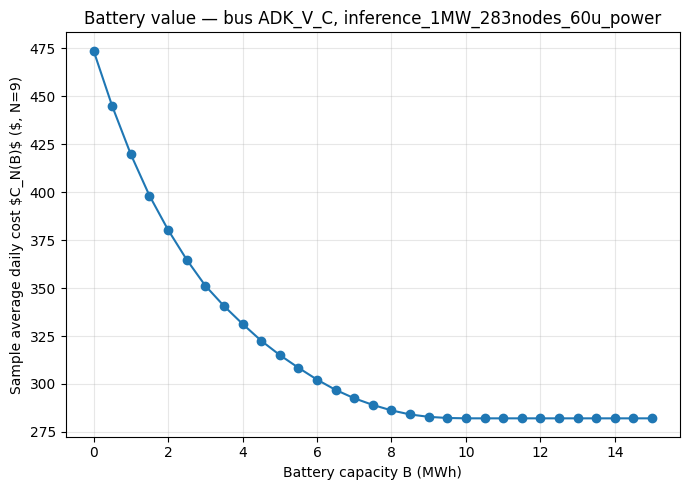

In [9]:
VIS_DIR.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(B_VALUES, C_N, marker="o")
ax.set_xlabel("Battery capacity B (MWh)")
ax.set_ylabel(f"Sample average daily cost $C_N(B)$ ($, N={N})")
ax.set_title(f"Battery value \u2014 bus {BUS_NAME}, {DEMAND_FILE.stem}")
ax.grid(True, alpha=0.3)
fig.tight_layout()
out_path = VIS_DIR / "cost_vs_battery_capacity.png"
fig.savefig(out_path, dpi=150)
print(f"Saved figure to {out_path}")
plt.show()